In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("data/Amazon Sale Report.csv")

C:\Users\saipr\AppData\Local\Temp\ipykernel_11420\2623025720.py:1: DtypeWarning: Columns (23: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/Amazon Sale Report.csv")


In [3]:
df.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [4]:
df.columns.tolist()

['index',
 'Order ID',
 'Date',
 'Status',
 'Fulfilment',
 'Sales Channel ',
 'ship-service-level',
 'Style',
 'SKU',
 'Category',
 'Size',
 'ASIN',
 'Courier Status',
 'Qty',
 'currency',
 'Amount',
 'ship-city',
 'ship-state',
 'ship-postal-code',
 'ship-country',
 'promotion-ids',
 'B2B',
 'fulfilled-by',
 'Unnamed: 22']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  str    
 2   Date                128975 non-null  str    
 3   Status              128975 non-null  str    
 4   Fulfilment          128975 non-null  str    
 5   Sales Channel       128975 non-null  str    
 6   ship-service-level  128975 non-null  str    
 7   Style               128975 non-null  str    
 8   SKU                 128975 non-null  str    
 9   Category            128975 non-null  str    
 10  Size                128975 non-null  str    
 11  ASIN                128975 non-null  str    
 12  Courier Status      122103 non-null  str    
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  str    
 15  Amount              121180 non-null  float64


In [6]:
df.isnull().sum()

index                     0
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6872
Qty                       0
currency               7795
Amount                 7795
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49153
B2B                       0
fulfilled-by          89698
Unnamed: 22           49050
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Unnamed: 22"].value_counts(dropna=False).head(10)

Unnamed: 22
False    79925
NaN      49050
Name: count, dtype: int64

In [9]:
df_clean = df.copy()

df_clean = df_clean.drop(columns=["Unnamed: 22"])

df_clean.columns = df_clean.columns.str.strip()

df_clean.shape

(128975, 23)

In [10]:
df_clean.isnull().sum()

index                     0
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6872
Qty                       0
currency               7795
Amount                 7795
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49153
B2B                       0
fulfilled-by          89698
dtype: int64

In [11]:
missing_percent = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_percent[missing_percent > 0].sort_values(ascending=False).round(2)

fulfilled-by        69.55
promotion-ids       38.11
currency             6.04
Amount               6.04
Courier Status       5.33
ship-state           0.03
ship-city            0.03
ship-country         0.03
ship-postal-code     0.03
dtype: float64

In [12]:
df_clean["Courier Status"] = df_clean["Courier Status"].fillna("Unknown")

df_clean["Courier Status"].isnull().sum()

np.int64(0)

In [13]:
df_clean[df_clean["Amount"].isnull()][["Amount", "currency"]].head(10)

,Amount,currency
8,NaN,NaN
29,NaN,NaN
65,NaN,NaN
84,NaN,NaN
95,NaN,NaN
101,NaN,NaN
132,NaN,NaN
139,NaN,NaN
155,NaN,NaN
165,NaN,NaN


In [14]:
amount_missing = df_clean["Amount"].isnull()
currency_missing = df_clean["currency"].isnull()

print("Missing Amount:", amount_missing.sum())
print("Missing currency:", currency_missing.sum())
print("Both missing:", (amount_missing & currency_missing).sum())
print("Amount missing but currency present:",
      (amount_missing & currency_missing.eq(False)).sum())
print("Currency missing but Amount present:",
      (currency_missing & amount_missing.eq(False)).sum())

Missing Amount: 7795
Missing currency: 7795
Both missing: 7795
Amount missing but currency present: 0
Currency missing but Amount present: 0


In [15]:
df_clean = df_clean.dropna(subset=["Amount"])

df_clean.shape

(121180, 23)

In [16]:
df_clean.isnull().sum()

index                     0
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status            0
Qty                       0
currency                  0
Amount                    0
ship-city                31
ship-state               31
ship-postal-code         31
ship-country             31
promotion-ids         41698
B2B                       0
fulfilled-by          83639
dtype: int64

In [17]:
# Fill missing promotion IDs
df_clean["promotion-ids"] = df_clean["promotion-ids"].fillna("No Promotion")

# Fill missing fulfilment details
df_clean["fulfilled-by"] = df_clean["fulfilled-by"].fillna("Unknown")

# Fill missing shipping details
shipping_columns = [
    "ship-city",
    "ship-state",
    "ship-postal-code",
    "ship-country"
]

df_clean[shipping_columns] = df_clean[shipping_columns].fillna("Unknown")

# Check missing values again
df_clean.isnull().sum()

index                 0
Order ID              0
Date                  0
Status                0
Fulfilment            0
Sales Channel         0
ship-service-level    0
Style                 0
SKU                   0
Category              0
Size                  0
ASIN                  0
Courier Status        0
Qty                   0
currency              0
Amount                0
ship-city             0
ship-state            0
ship-postal-code      0
ship-country          0
promotion-ids         0
B2B                   0
fulfilled-by          0
dtype: int64

In [18]:
df_clean.shape

(121180, 23)

In [19]:
df_clean.isnull().sum().sum()

np.int64(0)

In [20]:
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%m-%d-%y"
)

df_clean[["Date", "Amount", "Category"]].head()

,Date,Amount,Category
0,2022-04-30,647.62,Set
1,2022-04-30,406.00,kurta
2,2022-04-30,329.00,kurta
3,2022-04-30,753.33,Western Dress
4,2022-04-30,574.00,Top


In [21]:
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Month_Name"] = df_clean["Date"].dt.month_name()
df_clean["Year"] = df_clean["Date"].dt.year

df_clean[["Date", "Month", "Month_Name", "Year"]].head()

,Date,Month,Month_Name,Year
0,2022-04-30,4,April,2022
1,2022-04-30,4,April,2022
2,2022-04-30,4,April,2022
3,2022-04-30,4,April,2022
4,2022-04-30,4,April,2022


In [22]:
df_clean.dtypes

index                          int64
Order ID                         str
Date                  datetime64[us]
Status                           str
Fulfilment                       str
Sales Channel                    str
ship-service-level               str
Style                            str
SKU                              str
Category                         str
Size                             str
ASIN                             str
Courier Status                   str
Qty                            int64
currency                         str
Amount                       float64
ship-city                        str
ship-state                       str
ship-postal-code              object
ship-country                     str
promotion-ids                    str
B2B                             bool
fulfilled-by                     str
Month                          int32
Month_Name                       str
Year                           int32
dtype: object

In [23]:
# Total sales amount
total_sales = df_clean["Amount"].sum()

# Total quantity sold
total_quantity = df_clean["Qty"].sum()

# Total orders
total_orders = df_clean["Order ID"].nunique()

# Average order amount per row
average_amount = df_clean["Amount"].mean()

print("Total Sales Amount:", round(total_sales, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Unique Orders:", total_orders)
print("Average Amount per Row:", round(average_amount, 2))

Total Sales Amount: 78592678.3
Total Quantity Sold: 116482
Total Unique Orders: 113030
Average Amount per Row: 648.56


In [24]:
category_sales = (
    df_clean.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

category_sales.head(10)

Category
Set              39204124.03
kurta            21299546.70
Western Dress    11216072.69
Top               5347792.30
Ethnic Dress       791217.66
Blouse             458408.18
Bottom             150667.98
Saree              123933.76
Dupatta               915.00
Name: Amount, dtype: float64

In [25]:
import matplotlib.pyplot as plt

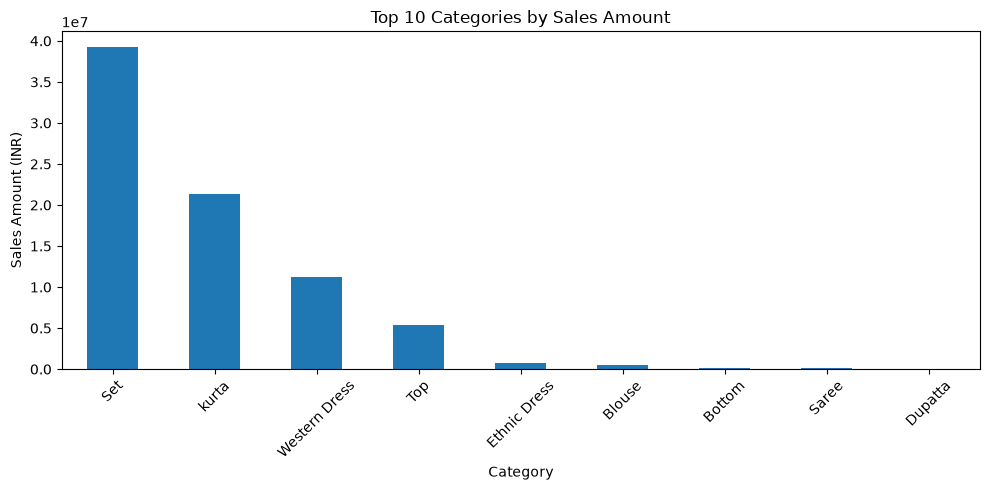

In [26]:
category_sales.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Categories by Sales Amount")
plt.xlabel("Category")
plt.ylabel("Sales Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# Monthly sales analysis
monthly_sales = (
    df_clean.groupby("Month_Name")["Amount"]
    .sum()
)

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order).dropna()

monthly_sales

Month_Name
March      101683.85
April    28838708.32
May      26226476.75
June     23425809.38
Name: Amount, dtype: float64

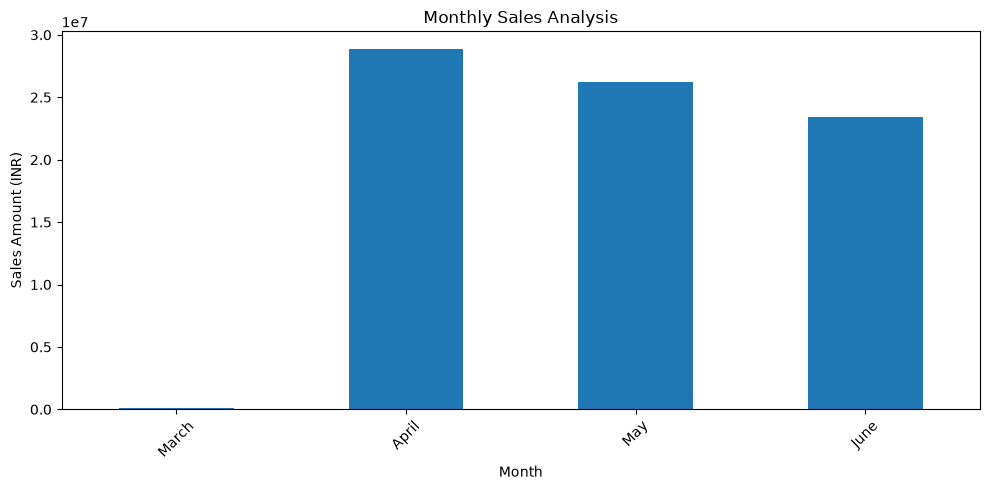

In [28]:
import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Sales Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# Count orders by status
status_counts = df_clean["Status"].value_counts()

print(status_counts)

Status
Shipped                          77596
Shipped - Delivered to Buyer     28761
Cancelled                        10766
Shipped - Returned to Seller      1950
Shipped - Picked Up                973
Pending                            656
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64


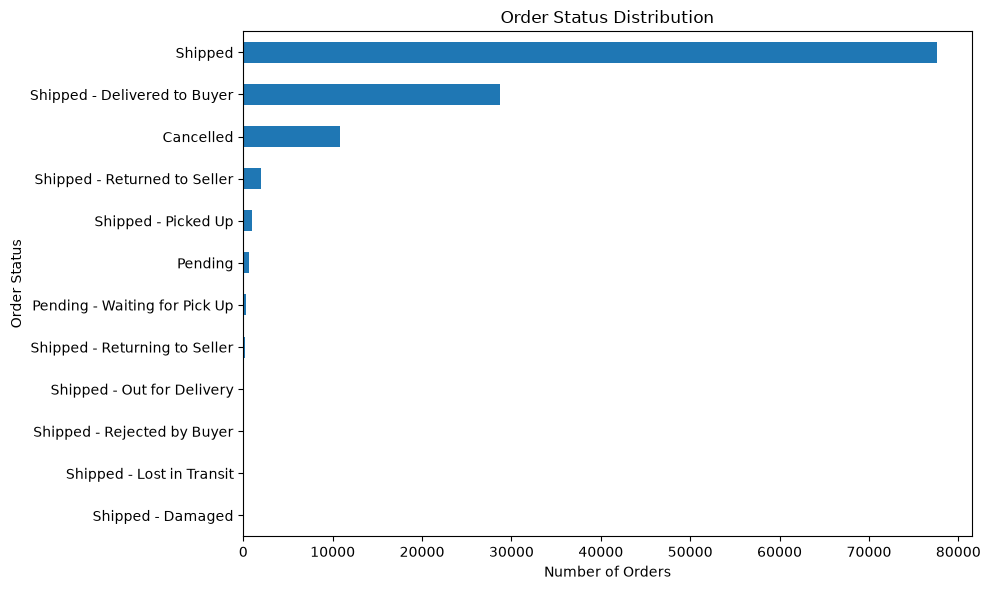

In [31]:
import matplotlib.pyplot as plt

status_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Order Status Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Order Status")
plt.tight_layout()
plt.show()

In [32]:
print(sorted(df_clean["Month"].unique()))

print(df_clean["Date"].min())
print(df_clean["Date"].max())

[np.int32(3), np.int32(4), np.int32(5), np.int32(6)]
2022-03-31 00:00:00
2022-06-29 00:00:00


In [33]:
# Calculate total sales by sales channel
channel_sales = (
    df_clean.groupby("Sales Channel")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(channel_sales)

Sales Channel
Amazon.in    78592678.3
Name: Amount, dtype: float64


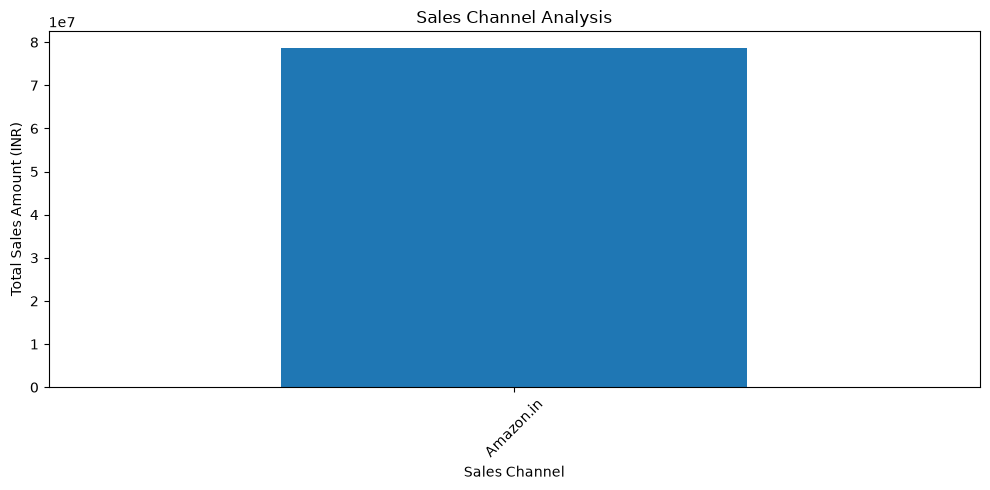

In [34]:
import matplotlib.pyplot as plt

channel_sales.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sales Channel Analysis")
plt.xlabel("Sales Channel")
plt.ylabel("Total Sales Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:

# Calculate total sales by fulfilment method
fulfilment_sales = (
    df_clean.groupby("Fulfilment")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(fulfilment_sales)


Fulfilment
Amazon      54322151.0
Merchant    24270527.3
Name: Amount, dtype: float64


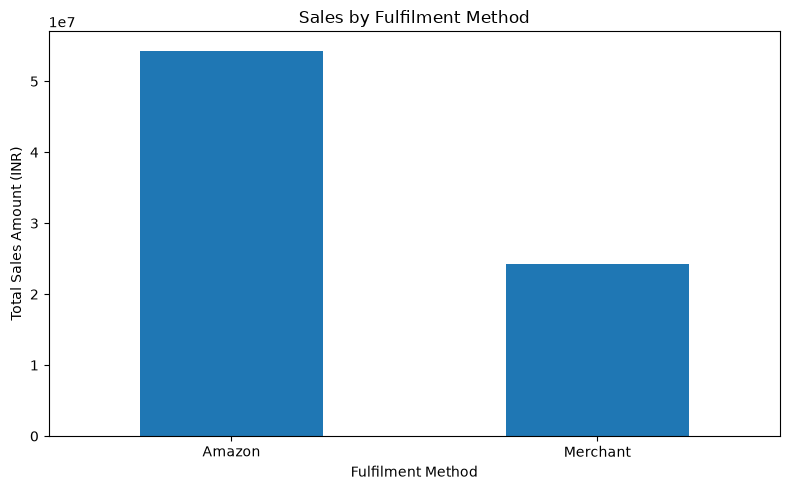

In [36]:

import matplotlib.pyplot as plt

fulfilment_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales by Fulfilment Method")
plt.xlabel("Fulfilment Method")
plt.ylabel("Total Sales Amount (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [37]:

# Calculate sales by customer type
b2b_sales = (
    df_clean.groupby("B2B")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(b2b_sales)


B2B
False    78001457.51
True       591220.79
Name: Amount, dtype: float64


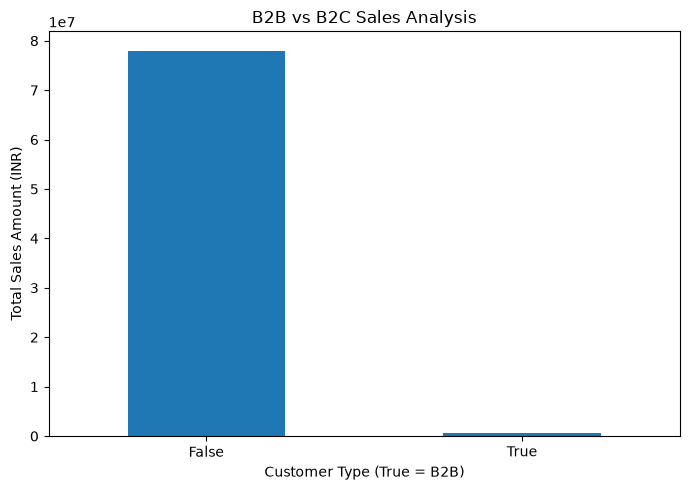

In [38]:

b2b_sales.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("B2B vs B2C Sales Analysis")
plt.xlabel("Customer Type (True = B2B)")
plt.ylabel("Total Sales Amount (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

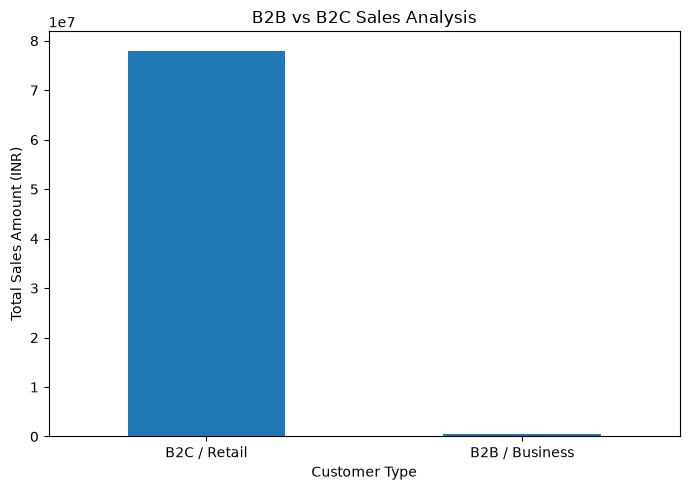

In [39]:

b2b_chart = b2b_sales.copy()

b2b_chart.index = [
    "B2C / Retail" if value == False else "B2B / Business"
    for value in b2b_chart.index
]

b2b_chart.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("B2B vs B2C Sales Analysis")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales Amount (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [40]:

state_sales = (
    df_clean.groupby("ship-state")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(state_sales)


ship-state
MAHARASHTRA       13335534.14
KARNATAKA         10481114.37
TELANGANA          6916615.65
UTTAR PRADESH      6816642.08
TAMIL NADU         6515650.11
DELHI              4235215.97
KERALA             3830227.58
WEST BENGAL        3507880.44
ANDHRA PRADESH     3219831.72
HARYANA            2882092.99
Name: Amount, dtype: float64


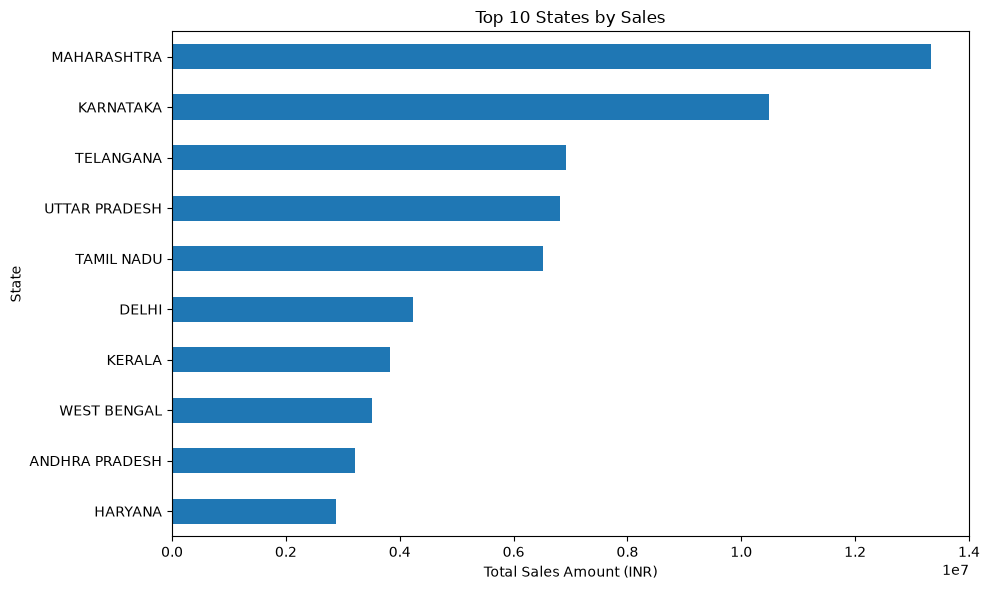

In [41]:
import matplotlib.pyplot as plt

state_sales = (
    df_clean.groupby("ship-state")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

state_sales.sort_values().plot(kind="barh")

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales Amount (INR)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

In [42]:
# Calculate total sales by month

monthly_sales = (
    df_clean.groupby("Month")["Amount"]
    .sum()
    .sort_index()
)

print(monthly_sales)

Month
3      101683.85
4    28838708.32
5    26226476.75
6    23425809.38
Name: Amount, dtype: float64


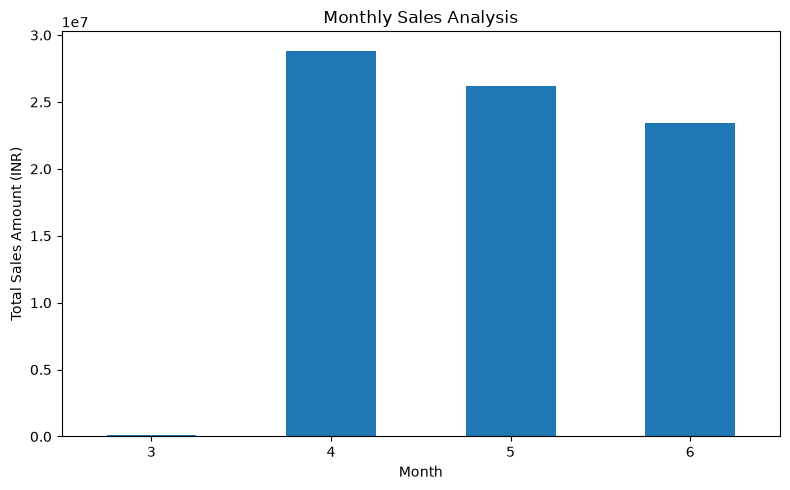

In [43]:
import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [44]:
# Calculate total sales by product category

category_sales = (
    df_clean.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Set              39204124.03
kurta            21299546.70
Western Dress    11216072.69
Top               5347792.30
Ethnic Dress       791217.66
Blouse             458408.18
Bottom             150667.98
Saree              123933.76
Dupatta               915.00
Name: Amount, dtype: float64


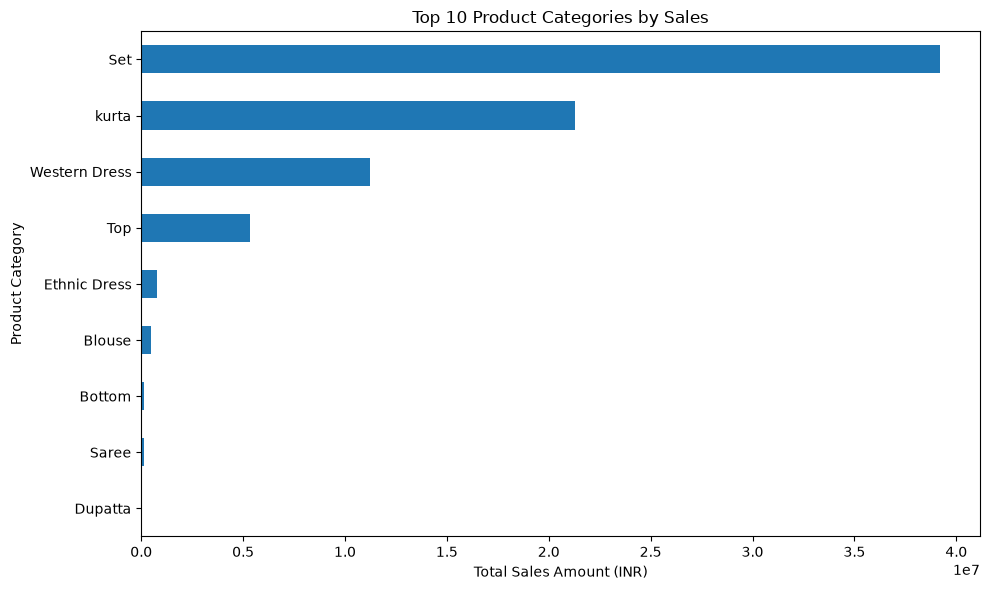

In [45]:
import matplotlib.pyplot as plt

category_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Total Sales Amount (INR)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [46]:
# Analyse order status

order_status = df_clean["Status"].value_counts()

print(order_status)

Status
Shipped                          77596
Shipped - Delivered to Buyer     28761
Cancelled                        10766
Shipped - Returned to Seller      1950
Shipped - Picked Up                973
Pending                            656
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64


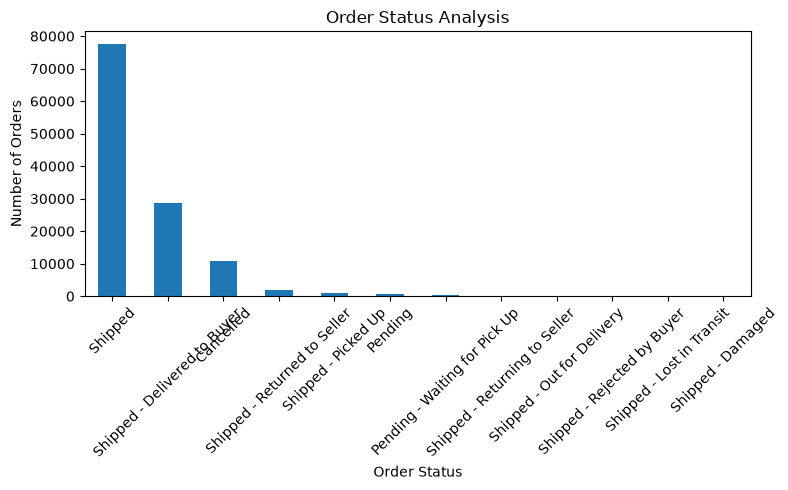

In [47]:
import matplotlib.pyplot as plt

order_status.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Order Status Analysis")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:

# Analyse order quantity

quantity_counts = df_clean["Qty"].value_counts().sort_index()

print(quantity_counts)


Qty
0      5136
1    115665
2       337
3        31
4         8
5         2
8         1
Name: count, dtype: int64


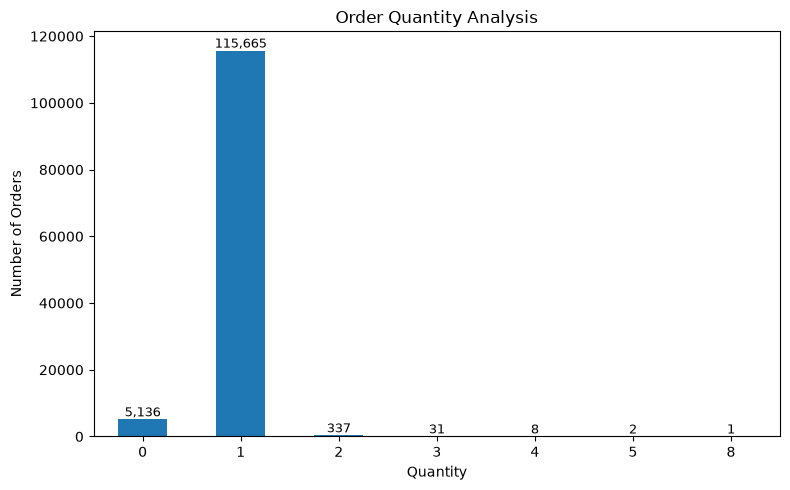

In [50]:

plt.figure(figsize=(8, 5))

ax = quantity_counts.plot(kind="bar")

plt.title("Order Quantity Analysis")
plt.xlabel("Quantity")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

# Display the number of orders above each bar
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height):,}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()


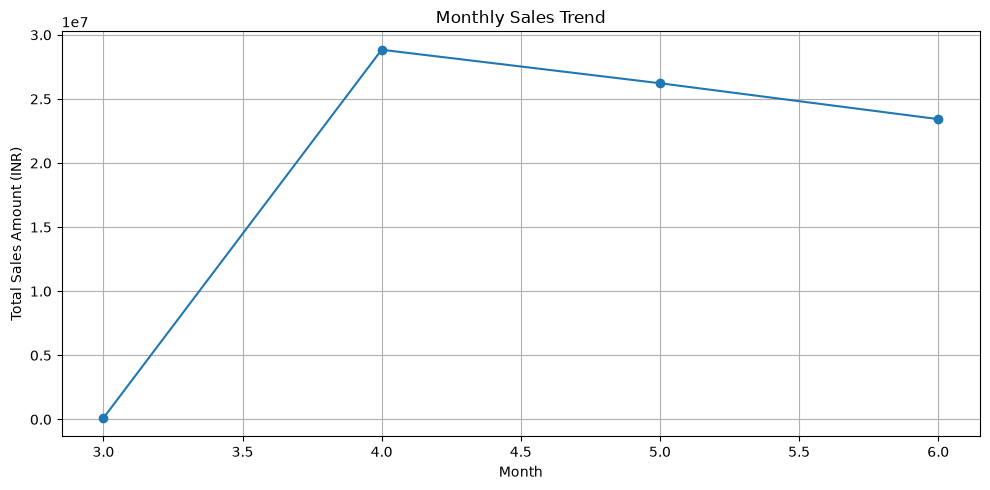

In [51]:

# Monthly Sales Trend - Line Chart

import matplotlib.pyplot as plt

monthly_sales = df_clean.groupby("Month")["Amount"].sum()

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount (INR)")
plt.grid(True)
plt.tight_layout()
plt.show()



## Key Business Insights

1. Maharashtra recorded the highest total sales among the states analyzed.
2. Karnataka and Telangana were also among the leading states by sales.
3. Set, Kurta, and Western Dress were the top three product categories by sales value.
4. Most records in the dataset had an order quantity of one.
5. Shipped orders represented the largest order-status category.
6. April had the highest monthly sales among the months displayed in the analysis.

## Conclusion

This project analyzed Amazon sales data using Python, Pandas, Matplotlib, and Seaborn. Data cleaning, exploratory data analysis, and visualizations were used to examine sales performance across states, product categories, months, customer types, order statuses, and quantities. The findings help identify high-performing regions and product categories and provide an overview of order patterns.
